# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3383 Матвеев Никита Сергеевич. Вариант №16.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

**Линейная дискретная система (ЛДС)** второго порядка задаётся передаточной функцией

$$ H(z) = \frac{b_0 + b_1 z^{-1} + b_2 z^{-2}}{a_0 + a_1 z^{-1} + a_2 z^{-2}}, \qquad a_0 = 1, $$

и эквивалентным разностным уравнение

$$ y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n-1) - a_2 y(n-2). $$

**Импульсная характеристика** $ h(n) $: реакция на цифровой единичный импульс $ u_0(n) $ при нулевых начальных условиях. Реакция на произвольное воздействие определяется формулой свёртки

$$ y(n) = \sum_{m=0}^{n} h(m)\,x(n-m). $$

**Нули**: корни числителя $ B(z) $, **полюсы**: корни знаменателя $ A(z) $. Причинная ЛДС устойчива, если все полюсы лежат строго внутри единичной окружности: $ |p_k| < 1 $.

**Частотная характеристика** получается подстановкой $ z = e^{j\hat\omega} $:

$$ H(e^{j\hat\omega}) = |H(e^{j\hat\omega})|\,e^{j\varphi(\hat\omega)}, \qquad \hat\omega = \omega T = 2\pi\frac{f}{f_{д}}, $$

где $ A(\hat\omega) = |H(e^{j\hat\omega})| $: АЧХ, $ \varphi(\hat\omega) = \arg H(e^{j\hat\omega}) $: ФЧХ. Частотная характеристика периодична с периодом $ 2\pi $, основная полоса $ [0; \pi] $, или $ [0; f_{д}/2] $ в Гц.

**ДПФ** последовательности длины $ N $ и **обратное ДПФ** (ОДПФ):

$$ X(k) = \sum_{n=0}^{N-1} x(n)\,e^{-j\frac{2\pi}{N}kn}, \qquad x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)\,e^{j\frac{2\pi}{N}kn}. $$

$ |X(k)| $: амплитудный спектр, $ \arg X(k) $: фазовый спектр. Дискретная нормированная частота $ k $ связана с частотой в Гц: $ f_k = k f_{д}/N $.

**Спектр конечной последовательнстии** непрерывен, а его отсчёты в точках $ \hat\omega_k = 2\pi k/N $ совпадают с $ X(k) $:

$$ X(e^{j\hat\omega}) = \sum_{n=0}^{N-1} x(n)\,e^{-j\hat\omega n}. $$

**Равенство Парсеваля**:

$$ \sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N}\sum_{k=0}^{N-1} |X(k)|^2. $$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Часть 1

#### Переменные варианта

Общий вид:

$$ b_0 = 0.5 + 0.02N_{вар}, \quad b_1 = b_0 (-1)^{N_{вар}+1}(0.9822 + 0.0178N_{вар}), \quad b_2 = b_0\big(0.8 + 0.2(N_{вар} \bmod 5)\big), $$

$$ a_0 = 1, \quad a_1 = (-1)^{N_{вар}}(0.7778 + 0.025N_{вар}), \quad a_2 = 0.64 + 0.006N_{вар}, $$

$$ N_1 = N_{вар} \bmod 10 + 20, \quad N_2 = N_{вар} \bmod 10 + 30, \quad f_{д} = 1000N_{вар}. $$

Для варианта 16:

$$ b_0 = 0.5 + 0.32 = 0.82, \quad b_1 = 0.82\cdot(-1)^{17}\cdot(0.9822 + 0.2848) = -0.82\cdot 1.267 = -1.03894, \quad b_2 = 0.82\cdot(0.8 + 0.2\cdot 1) = 0.82, $$

$$ a_1 = (-1)^{16}\cdot(0.7778 + 0.4) = 1.1778, \quad a_2 = 0.64 + 0.096 = 0.736, $$

$$ N_1 = 6 + 20 = 26, \quad N_2 = 6 + 30 = 36, \quad f_{д} = 16000 \text{ Гц}. $$

Передаточная функция:

$$ H(z) = \frac{0.82 - 1.03894z^{-1} + 0.82z^{-2}}{1 + 1.1778z^{-1} + 0.736z^{-2}}. $$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams['figure.figsize'] = (10, 3.5)
plt.rcParams['axes.grid'] = True

Nv = 16
b0 = 0.5 + 0.02 * Nv
b = np.array([b0, b0 * (-1)**(Nv + 1) * (0.9822 + 0.0178 * Nv), b0 * (0.8 + 0.2 * (Nv % 5))])
a = np.array([1, (-1)**Nv * (0.7778 + 0.025 * Nv), 0.64 + 0.006 * Nv])
N1 = Nv % 10 + 20
N2 = Nv % 10 + 30
fs1 = 1000 * Nv

for name, v in (('b', b), ('a', a)):
    print(f'{name}0 = {v[0]:8.5f}   {name}1 = {v[1]:8.5f}   {name}2 = {v[2]:8.5f}')
print(f'N1 = {N1}, N2 = {N2}, fd = {fs1} Гц')

b0 =  0.82000   b1 = -1.03894   b2 =  0.82000
a0 =  1.00000   a1 =  1.17780   a2 =  0.73600
N1 = 26, N2 = 36, fd = 16000 Гц


#### Пункт 1. Импульсная характеристика

**Что ищем:** отсчёты $ h(n) $, $ n = 0 \ldots N_1 - 1 $.

В общем виде подаём на вход единичный импульс $ u_0(n) $ при нулевых начальных условиях ($ h(-1) = h(-2) = 0 $):

$$ h(n) = b_0u_0(n) + b_1u_0(n-1) + b_2u_0(n-2) - a_1 h(n-1) - a_2 h(n-2). $$

Первые три отсчёта содержат вклад числителя, дальше работает только обратная связь:

$$ h(0) = b_0, \qquad h(1) = b_1 - a_1 h(0), \qquad h(2) = b_2 - a_1 h(1) - a_2 h(0), \qquad h(n) = -a_1 h(n-1) - a_2 h(n-2),\ n \geqslant 3. $$

Подставляем значения варианта 16:

$$ h(0) = 0.82, $$

$$ h(1) = -1.03894 - 1.1778\cdot 0.82 = -1.03894 - 0.96580 = -2.00474, $$

$$ h(2) = 0.82 - 1.1778\cdot(-2.00474) - 0.736\cdot 0.82 = 0.82 + 2.36118 - 0.60352 = 2.57766, $$

$$ h(3) = -1.1778\cdot 2.57766 - 0.736\cdot(-2.00474) = -3.03597 + 1.47549 = -1.56048. $$

Остальные отсчёты считаем рекуррентно в коде (`lfilter` решает разностное уравнение).

h(0..3) = [ 0.82    -2.00474  2.57766 -1.56048]


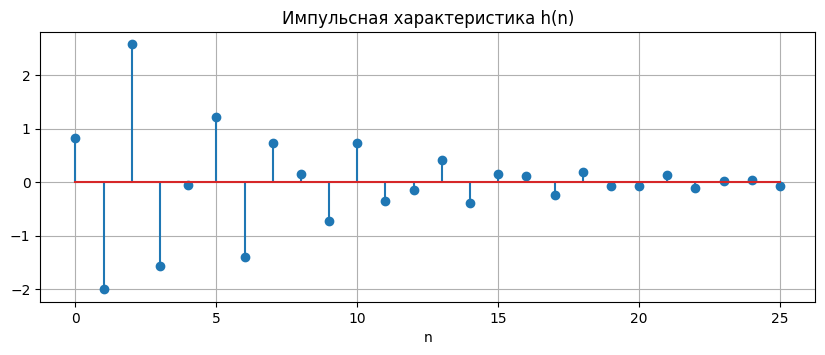

In [2]:
n1 = np.arange(N1)
delta = (n1 == 0).astype(float)
h = signal.lfilter(b, a, delta)

print('h(0..3) =', np.round(h[:4], 5))
plt.stem(n1, h)
plt.title('Импульсная характеристика h(n)')
plt.xlabel('n')
plt.show()

Выведем аналитическую формулу $ h(n) $.

Общий вид. Полюсы звена: комплексно-сопряжённая пара $ p_{1,2} = r e^{\pm j\theta} $. Из теоремы Виета для $ z^2 + a_1 z + a_2 = 0 $:

$$ r^2 = a_2, \qquad 2r\cos\theta = -a_1 \quad\Rightarrow\quad r = \sqrt{a_2}, \qquad \theta = \arccos\left(-\frac{a_1}{2\sqrt{a_2}}\right). $$

Порядки числителя и знаменателя равны, поэтому выделяем целую часть $ C_0 $ и раскладываем остаток на простые дроби:

$$ H(z) = C_0 + \frac{R}{1 - p_1 z^{-1}} + \frac{R^*}{1 - p_2 z^{-1}}, \qquad C_0 = \frac{b_2}{a_2}, \qquad R = \Big[(1 - p_1z^{-1})H(z)\Big]_{z = p_1}. $$

По таблице Z-преобразований $ C_0 \leftrightarrow C_0u_0(n) $, $ \dfrac{R}{1 - p z^{-1}} \leftrightarrow R p^n $. Сумма сопряжённых слагаемых вещественна:

$$ Rr^n e^{j\theta n} + R^*r^n e^{-j\theta n} = 2|R|r^n\cos(\theta n + \psi), \qquad \psi = \arg R, $$

$$ h(n) = C_0\,u_0(n) + 2|R|\,r^n\cos(\theta n + \psi), \quad n \geqslant 0. $$

Вариант 16:

$$ r = \sqrt{0.736} = 0.8579, \qquad \cos\theta = -\frac{1.1778}{2\cdot 0.8579} = -0.6864 \ \Rightarrow\ \theta = 0.7408\pi, $$

$$ C_0 = \frac{0.82}{0.736} = 1.1141, \qquad R = -0.1471 + j1.7456 = 1.7517\,e^{j0.5268\pi}. $$

Находим эти величины в коде и сравниваем формулу с численным расчётом.

In [3]:
r, p, k = signal.residuez(b, a)
C0 = k[0]
R, psi = abs(r[0]), np.angle(r[0])
rho, theta = abs(p[0]), np.angle(p[0])
print(f'r = sqrt(a2) = {np.sqrt(a[2]):.4f}, theta = arccos(-a1/(2r)) = {np.arccos(-a[1] / (2 * np.sqrt(a[2]))) / np.pi:.4f}pi')
print(f'C0 = {C0:.4f}, R = {r[0]:.4f}, |R| = {R:.4f}, psi = {psi/np.pi:.4f}pi')

h_an = C0 * delta + 2 * R * rho**n1 * np.cos(theta * n1 + psi)
print('max |h - h_an| =', np.max(abs(h - h_an)))

r = sqrt(a2) = 0.8579, theta = arccos(-a1/(2r)) = 0.7408pi
C0 = 1.1141, R = -0.1471+1.7456j, |R| = 1.7517, psi = 0.5268pi
max |h - h_an| = 1.5265566588595902e-15


Аналитическая формула импульсной характеристики:

$$ h(n) = 1.1141\,u_0(n) + 3.5035\cdot 0.8579^n \cos(0.7408\pi n + 0.5268\pi), \quad n \geqslant 0. $$

Она совпадает с численным расчётом с точностью до ошибок округления.

**Длина импульсной характеристики.** Звено рекурсивное, полюсы не сокращаются нулями, поэтому $ h(n) $ в действительности бесконечна (БИХ-звено) и лишь затухает как $ r^n = 0.8579^n $. Длина $ N_1 = 26 $ означает лишь интервал, на котором она вычислена: $ |h(25)| \approx 0.075 \neq 0 $.

#### Пункт 2. Реакция по формуле свёртки

Зададим воздействие $ x(n) $: прямоугольный импульс.

В общем виде:

$$ x(n) = \begin{cases} 1, & 0 \leqslant n < int(N_2/2) \\ 0, & int(N_2/2) \leqslant n \leqslant N_2 - 1 \end{cases} $$

Для варианта 16: $ int(36/2) = 18 $, т.е. $ x(n) = 1 $ при $ n = 0 \ldots 17 $ и $ x(n) = 0 $ при $ n = 18 \ldots 35 $.

Длина импульса: 18 | длина воздействия: 36


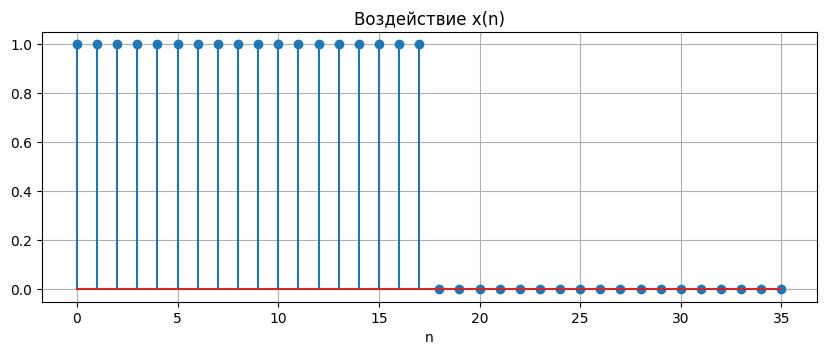

In [4]:
n2 = np.arange(N2)
x = (n2 < round(N2 / 2)).astype(float)
print('Длина импульса:', int(x.sum()), '| длина воздействия:', len(x))

plt.stem(n2, x)
plt.title('Воздействие x(n)')
plt.xlabel('n')
plt.show()

Найдём реакцию $ y_1(n) $ и длину свёртки.

Общий вид формулы свёртки:

$$ y(n) = \sum_{m=0}^{n} h(m)\,x(n-m). $$

Длина линейной свёртки последовательностей длин $ N_1 $ и $ N_2 $:

$$ L = N_1 + N_2 - 1. $$

Если ненулевые отсчёты $ x(n) $ занимают $ n = 0 \ldots L_x - 1 $, то последний ненулевой отсчёт свёртки имеет номер $ (L_x - 1) + (N_1 - 1) $.

Подставляем значения варианта 16:

$$ L = 26 + 36 - 1 = 61, \qquad n_{max} = 17 + 25 = 42. $$

Значит, ненулевая часть свёртки содержит 43 отсчёта.

Например, первые отсчёты: $ y(0) = h(0) = 0.82 $, $ y(1) = h(0) + h(1) = 0.82 - 2.00474 = -1.18474 $.

N1 + N2 - 1 = 61, длина вычисленной свёртки = 61
Последний ненулевой отсчёт: n = 42, ненулевых отсчётов: 43
y(0..1) = [ 0.82    -1.18474]


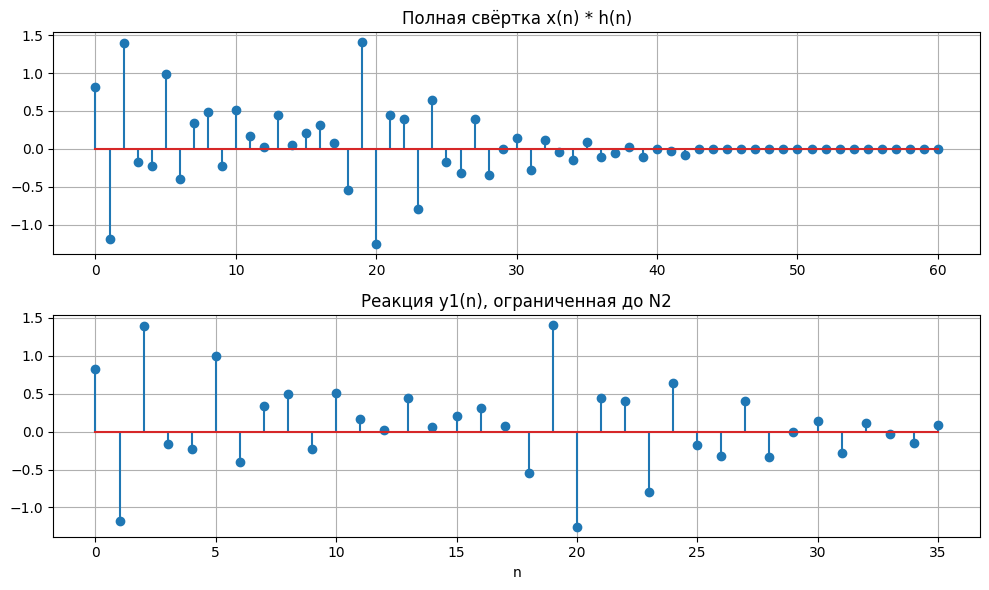

In [5]:
y_full = np.convolve(x, h)
y1 = y_full[:N2]
nz = np.nonzero(abs(y_full) > 1e-12)[0]
print(f'N1 + N2 - 1 = {N1 + N2 - 1}, длина вычисленной свёртки = {len(y_full)}')
print(f'Последний ненулевой отсчёт: n = {nz.max()}, ненулевых отсчётов: {nz.max() + 1}')
print('y(0..1) =', np.round(y_full[:2], 5))

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].stem(np.arange(len(y_full)), y_full); ax[0].set_title('Полная свёртка x(n) * h(n)')
ax[1].stem(n2, y1); ax[1].set_title('Реакция y1(n), ограниченная до N2')
ax[1].set_xlabel('n')
plt.tight_layout()
plt.show()

1. Длина импульса $ x $ равна $ int(N_2/2) = 18 $ отсчётов; длина всего воздействия $ N_2 = 36 $.
2. Длина свёртки аналитически $ N_1 + N_2 - 1 = 61 $ отсчёт ($ n = 0 \ldots 60 $). По графику ненулевая часть занимает $ n = 0 \ldots 42 $, т.е. 43 отсчёта, так как последние 18 отсчётов воздействия нулевые.
3. Реакцию ограничивают длиной воздействия, потому что $ h(n) $ искусственно усечена до $ N_1 $ отсчётов: отсчёты свёртки после $ n = N_2 - 1 $ определяются усечением, а не реальной системой. Кроме того, это интервал наблюдения, на котором реакция сравнивается с решением разностного уравнения (п. 3), имеющим ту же длину.

#### Пункт 3. Реакция по разностному уравнению

**Что ищем:** реакцию $ y_2(n) $ на то же воздействие.

В общем случае из $ H(z) = Y(z)/X(z) $ получаем $ Y(z)A(z) = X(z)B(z) $. Переходя к оригиналам ($ z^{-m} \leftrightarrow $ задержка на $ m $ отсчётов):

$$ y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n-1) - a_2 y(n-2). $$

Вариант 16:

$$ y(n) = 0.82\,x(n) - 1.03894\,x(n-1) + 0.82\,x(n-2) - 1.1778\,y(n-1) - 0.736\,y(n-2). $$

Первые отсчёты при нулевых начальных условиях:

$$ y(0) = 0.82\cdot 1 = 0.82, \qquad y(1) = 0.82 - 1.03894 - 1.1778\cdot 0.82 = -1.18474. $$

Они совпадают с отсчётами свёртки из п. 2.

Длина воздействия: 36 | длина реакции: 36
y2(0..1) = [ 0.82    -1.18474]


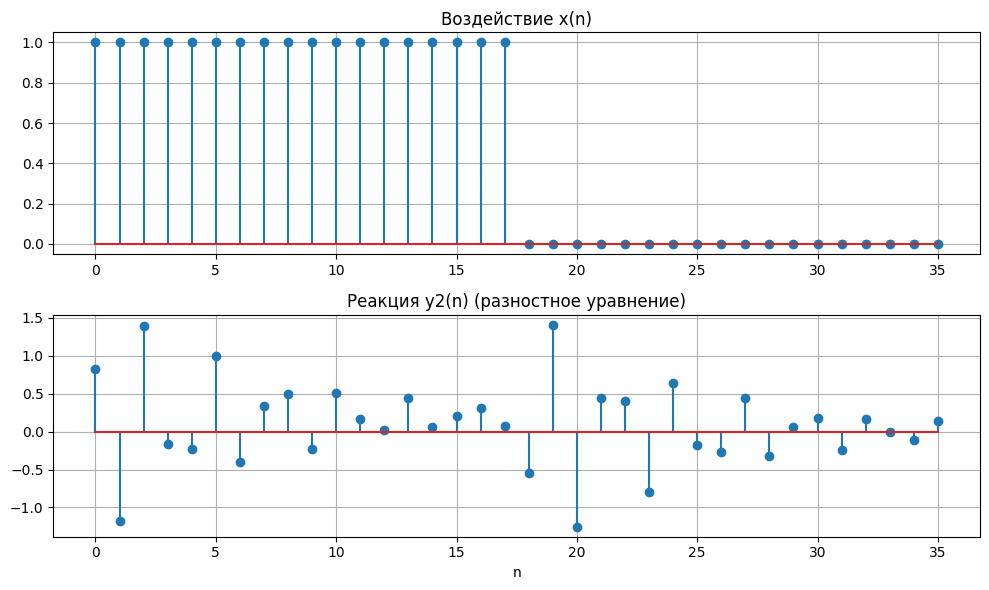

In [6]:
y2 = signal.lfilter(b, a, x)
print('Длина воздействия:', len(x), '| длина реакции:', len(y2))
print('y2(0..1) =', np.round(y2[:2], 5))

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].stem(n2, x); ax[0].set_title('Воздействие x(n)')
ax[1].stem(n2, y2); ax[1].set_title('Реакция y2(n) (разностное уравнение)')
ax[1].set_xlabel('n')
plt.tight_layout()
plt.show()

Оценим расхождение реакций $ |y_1(n) - y_2(n)| $.

При $ n \leqslant N_1 - 1 $ в свёртке участвуют только вычисленные отсчёты $ h(0) \ldots h(n) $, поэтому реакции должны совпадать. При $ n \geqslant N_1 $ в точной реакции нужны отсчёты $ h(m) $ с $ m \geqslant N_1 $, которых в усечённой $ h(n) $ нет.

max |y1 - y2| при n < N1: 6.66e-16
max |y1 - y2| при n >= N1: 0.0556 (n = 29)


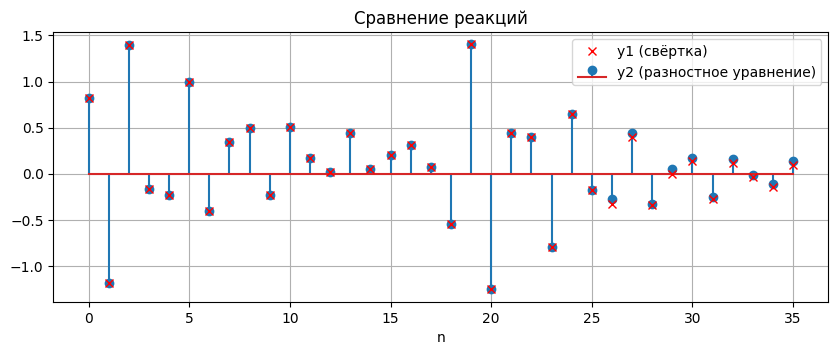

In [7]:
d = abs(y1 - y2)
print(f'max |y1 - y2| при n < N1: {d[:N1].max():.2e}')
print(f'max |y1 - y2| при n >= N1: {d[N1:].max():.4f} (n = {N1 + np.argmax(d[N1:])})')

plt.stem(n2, y2, label='y2 (разностное уравнение)')
plt.plot(n2, y1, 'rx', label='y1 (свёртка)')
plt.title('Сравнение реакций'); plt.xlabel('n'); plt.legend()
plt.show()

Длины воздействия и реакции совпадают и равны $ N_2 = 36 $: реакция вычисляется рекуррентно на том же интервале, что и воздействие. Теоретически реакция рекурсивного звена бесконечна и затухает.

Реакции совпадают при $ n < N_1 = 26 $. При $ n \geqslant 26 $ появляется небольшое расхождение (максимум $ \approx 0.056 $), так как $ y_1(n) $ вычислена с усечённой импульсной характеристикой, а $ y_2(n) $: точная реакция звена.

#### Пункт 4. Нули и полюсы

Найдём нули и полюсы в алгебраической и показательной формах.

Общий вид. Умножив числитель и знаменатель $ H(z) $ на $ z^2 $:

$$ H(z) = \frac{b_0 z^2 + b_1 z + b_2}{z^2 + a_1 z + a_2}, $$

$$ z_{1,2} = \frac{-b_1 \pm j\sqrt{4b_0b_2 - b_1^2}}{2b_0}, \qquad p_{1,2} = \frac{-a_1 \pm j\sqrt{4a_2 - a_1^2}}{2}. $$

Показательная форма $ z = r e^{j\varphi} $: $ r = \sqrt{(\mathrm{Re}\,z)^2 + (\mathrm{Im}\,z)^2} $, $ \varphi = \operatorname{atan2}(\mathrm{Im}\,z, \mathrm{Re}\,z) $. По теореме Виета $ |z_{1,2}|^2 = b_2/b_0 $, $ |p_{1,2}|^2 = a_2 $.

Вариант 16, нули:

$$ 4b_0b_2 - b_1^2 = 2.6896 - 1.07940 = 1.61020, \quad \sqrt{1.61020} = 1.26894, $$

$$ z_{1,2} = \frac{1.03894 \pm j1.26894}{1.64} = 0.63350 \pm j0.77374, $$

$$ |z_{1,2}| = \sqrt{0.82/0.82} = 1, \qquad \arg z_1 = \arctan\frac{0.77374}{0.63350} = 0.88469 = 0.2816\pi. $$

Вариант 16, полюсы:

$$ 4a_2 - a_1^2 = 2.944 - 1.38722 = 1.55679, \quad \sqrt{1.55679} = 1.24771, $$

$$ p_{1,2} = \frac{-1.1778 \pm j1.24771}{2} = -0.58890 \pm j0.62386, $$

$$ |p_{1,2}| = \sqrt{0.736} = 0.85790, \qquad \arg p_1 = \pi - \arctan\frac{0.62386}{0.58890} = \pi - 0.81437 = 2.32722 = 0.7408\pi. $$

In [8]:
zeros, poles, gain = signal.tf2zpk(b, a)
for name, v in (('Нули', zeros), ('Полюсы', poles)):
    print(name)
    for q in v:
        print(f'  {q.real:+.5f} {q.imag:+.5f}j = {abs(q):.5f} * exp(j * {np.angle(q)/np.pi:+.4f}pi)')

Нули
  +0.63350 +0.77374j = 1.00000 * exp(j * +0.2816pi)
  +0.63350 -0.77374j = 1.00000 * exp(j * -0.2816pi)
Полюсы
  -0.58890 +0.62386j = 0.85790 * exp(j * +0.7408pi)
  -0.58890 -0.62386j = 0.85790 * exp(j * -0.7408pi)


Связь между нулями и полюсами: коэффициенты $ H(z) $ вещественны, поэтому и нули, и полюсы образуют комплексно-сопряжённые пары: модули одинаковы, аргументы противоположны по знаку. Так как $ b_0 = b_2 $, нули лежат точно на единичной окружности.

Запишем $ H(z) $ в виде произведения простейших множителей.

В общем виде:

$$ H(z) = b_0\,\frac{(1 - z_1z^{-1})(1 - z_2z^{-1})}{(1 - p_1z^{-1})(1 - p_2z^{-1})}. $$

Для варианта 16:

$$ H(z) = 0.82\,\frac{(1 - e^{j0.2816\pi}z^{-1})(1 - e^{-j0.2816\pi}z^{-1})}{(1 - 0.8579\,e^{j0.7408\pi}z^{-1})(1 - 0.8579\,e^{-j0.7408\pi}z^{-1})}. $$

Проверка: перемножение пары множителей даёт $ (1 - z_1z^{-1})(1 - z_2z^{-1}) = 1 - 2r\cos\varphi\,z^{-1} + r^2z^{-2} $, т.е. для знаменателя $ 1 - 2\cdot 0.8579\cos(0.7408\pi)z^{-1} + 0.736z^{-2} = 1 + 1.1778z^{-1} + 0.736z^{-2} $.

In [9]:
b_chk = gain * np.real(np.poly(zeros))
a_chk = np.real(np.poly(poles))
print('b из нулей:', np.round(b_chk, 5).tolist())
print('a из полюсов:', np.round(a_chk, 5).tolist())

b из нулей: [0.82, -1.03894, 0.82]
a из полюсов: [1.0, 1.1778, 0.736]


#### Пункт 5. Карта нулей и полюсов

**Что ищем:** положение нулей и полюсов относительно единичной окружности.

Общий вид критерия устойчивости:

$$ |p_k| < 1, \quad k = 1, 2. $$

Подставляем значения варианта 16: $ |p_{1,2}| = 0.8579 < 1 $.

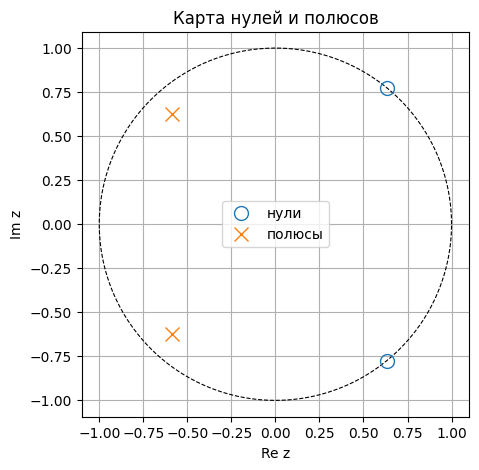

|полюсы| = [0.8579 0.8579] -> устойчиво: True


In [10]:
t = np.linspace(0, 2 * np.pi, 400)
plt.figure(figsize=(5, 5))
plt.plot(np.cos(t), np.sin(t), 'k--', lw=0.8)
plt.plot(zeros.real, zeros.imag, 'o', mfc='none', ms=10, label='нули')
plt.plot(poles.real, poles.imag, 'x', ms=10, label='полюсы')
plt.axis('equal'); plt.xlabel('Re z'); plt.ylabel('Im z')
plt.title('Карта нулей и полюсов'); plt.legend()
plt.show()
print('|полюсы| =', np.round(abs(poles), 4), '-> устойчиво:', np.all(abs(poles) < 1))

1. Звено устойчиво: оба полюса лежат внутри единичной окружности ($ |p_{1,2}| = 0.8579 < 1 $), поэтому $ h(n) \to 0 $.
2. Положение маркеров на карте совпадает со значениями п. 4: нули на окружности под углами $ \pm 0.2816\pi $ ($ \approx \pm 51^\circ $), полюсы внутри под углами $ \pm 0.7408\pi $ ($ \approx \pm 133^\circ $).

#### Пункт 6. АЧХ и ФЧХ в шкале нормированных частот

Вычислим $ A(\hat\omega) $ и $ \varphi(\hat\omega) $ на $ \hat\omega \in [0; \pi] $.

В общем виде:

$$ H(e^{j\hat\omega}) = \frac{b_0 + b_1 e^{-j\hat\omega} + b_2 e^{-j2\hat\omega}}{1 + a_1 e^{-j\hat\omega} + a_2 e^{-j2\hat\omega}}, \qquad A(\hat\omega) = |H(e^{j\hat\omega})|, \quad \varphi(\hat\omega) = \arg H(e^{j\hat\omega}). $$

Геометрический смысл через нули и полюсы:

$$ A(\hat\omega) = b_0\,\frac{|e^{j\hat\omega} - z_1|\cdot|e^{j\hat\omega} - z_2|}{|e^{j\hat\omega} - p_1|\cdot|e^{j\hat\omega} - p_2|} $$

Это отношение произведений расстояний от точки $ e^{j\hat\omega} $ на единичной окружности до нулей и до полюсов.

Вариант 16:

$$ H(e^{j\hat\omega}) = \frac{0.82 - 1.03894 e^{-j\hat\omega} + 0.82 e^{-j2\hat\omega}}{1 + 1.1778 e^{-j\hat\omega} + 0.736 e^{-j2\hat\omega}}. $$

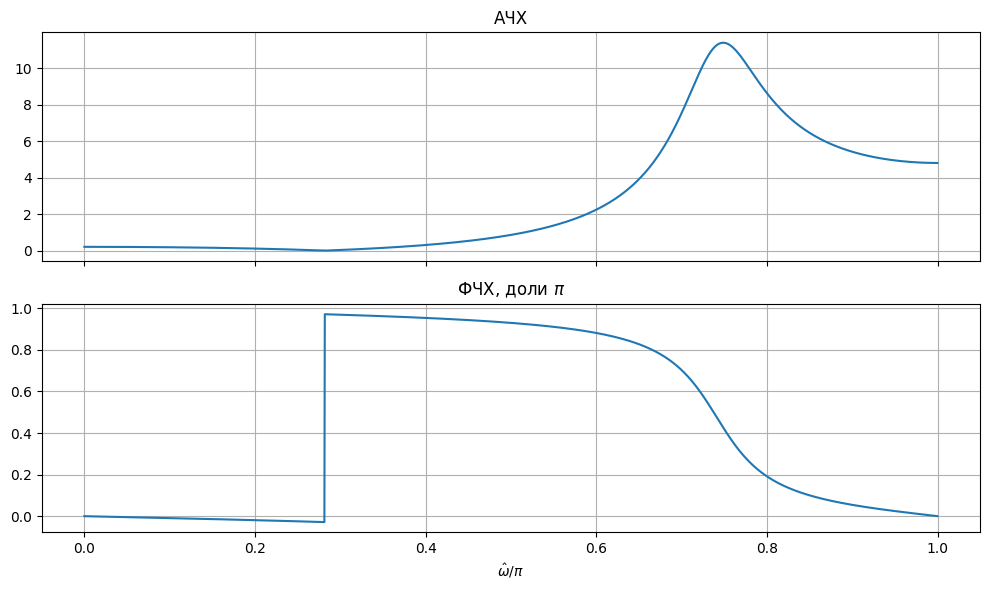

In [11]:
w, H = signal.freqz(b, a, worN=2048)

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(w / np.pi, abs(H)); ax[0].set_title('АЧХ')
ax[1].plot(w / np.pi, np.angle(H) / np.pi); ax[1].set_title(r'ФЧХ, доли $\pi$')
ax[1].set_xlabel(r'$\hat\omega/\pi$')
plt.tight_layout()
plt.show()

Найдём значения АЧХ на границах полосы, минимум и максимум.

Общий вид. При $ \hat\omega = 0 $: $ e^{-j\hat\omega} = 1 $; при $ \hat\omega = \pi $: $ e^{-j\hat\omega} = -1 $:

$$ A(0) = \left|\frac{b_0 + b_1 + b_2}{1 + a_1 + a_2}\right|, \qquad A(\pi) = \left|\frac{b_0 - b_1 + b_2}{1 - a_1 + a_2}\right|. $$

Для варианта 16:

$$ A(0) = \frac{0.82 - 1.03894 + 0.82}{1 + 1.1778 + 0.736} = \frac{0.60106}{2.9138} = 0.2063, \qquad A(\pi) = \frac{0.82 + 1.03894 + 0.82}{1 - 1.1778 + 0.736} = \frac{2.67894}{0.5582} = 4.7992. $$

Минимум ожидаем при $ \hat\omega = \arg z_1 = 0.2816\pi $ (точка окружности совпадает с нулём), максимум: вблизи $ \hat\omega = \arg p_1 = 0.7408\pi $ (ближе всего к полюсу).

In [12]:
A0 = abs(sum(b) / sum(a))
Api = abs((b[0] - b[1] + b[2]) / (a[0] - a[1] + a[2]))
print(f'A(0) = {A0:.4f}, A(pi) = {Api:.4f}')
print(f'Минимум АЧХ: {abs(H).min():.4f} при w = {w[np.argmin(abs(H))]/np.pi:.4f}pi')
print(f'Максимум АЧХ: {abs(H).max():.4f} при w = {w[np.argmax(abs(H))]/np.pi:.4f}pi')

A(0) = 0.2063, A(pi) = 4.7992
Минимум АЧХ: 0.0002 при w = 0.2817pi
Максимум АЧХ: 11.3850 при w = 0.7485pi


1. Границы основной полосы: $ \hat\omega \in [0; \pi] $; с учётом отрицательных частот: $ [-\pi; \pi] $. Частотная характеристика периодична с периодом $ 2\pi $, АЧХ чётна, ФЧХ нечётна.
2. Нуль на единичной окружности под углом $ 0.2816\pi $ даёт нулевое значение АЧХ при $ \hat\omega = 0.2816\pi $. Полюс под углом $ 0.7408\pi $, близкий к окружности ($ |p_{1,2}| = 0.858 $), даёт резонансный максимум $ \approx 11.4 $ около $ \hat\omega \approx 0.75\pi $.
3. Скачок ФЧХ на $ \pi $ находится при $ \hat\omega = 0.2816\pi $ и соответствует нулевому значению АЧХ: при прохождении через ноль $ H(e^{j\hat\omega}) $ меняет знак.
4. $ A(0) \approx 0.21 $, $ A(\pi) \approx 4.8 $: низкочастотные составляющие воздействия преимущественно подавлены, высокочастотные усилены. Поэтому на плоских участках прямоугольного импульса (постоянная составляющая) реакция мала, а колебания возникают на его фронтах.

#### Пункт 7. АЧХ и ФЧХ в шкале частот $ f $ (Гц)

Построим те же характеристики по оси частот в Гц.

Связь шкал:

$$ \hat\omega = \frac{2\pi f}{f_{д}} \quad\Leftrightarrow\quad f = \frac{\hat\omega f_{д}}{2\pi}. $$

Подставляем значения варианта 16: $ f_{д} = 16000 $ Гц, граница полосы $ f_{д}/2 = 8000 $ Гц;

$$ f_{min} = 0.2816\cdot 8000 = 2253 \text{ Гц}, \qquad f_{max} = 0.7485\cdot 8000 = 5988 \text{ Гц}. $$

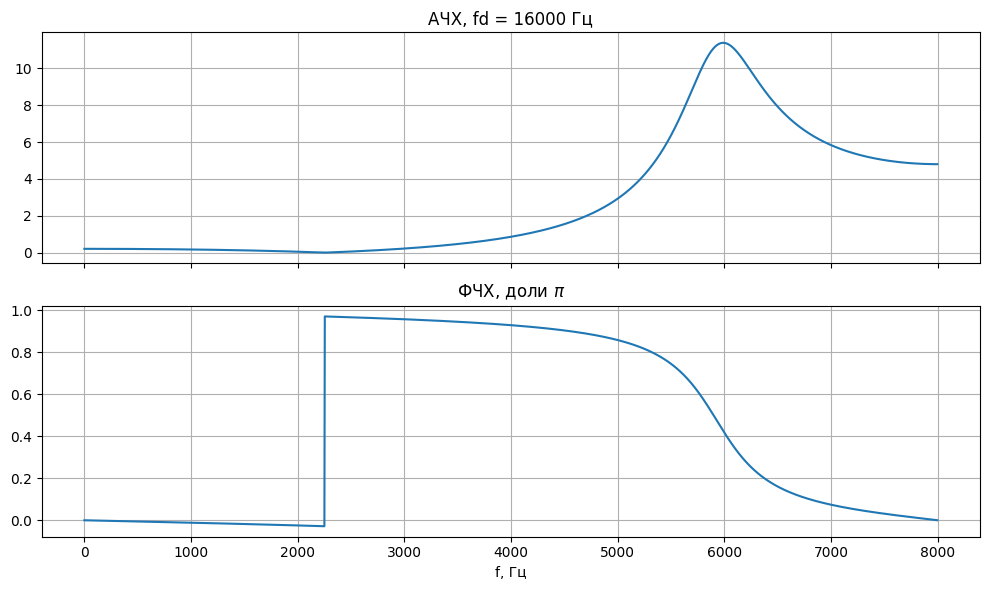

Нуль АЧХ: 2254 Гц, максимум: 5988 Гц


In [13]:
f = w * fs1 / (2 * np.pi)

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(f, abs(H)); ax[0].set_title(f'АЧХ, fd = {fs1} Гц')
ax[1].plot(f, np.angle(H) / np.pi); ax[1].set_title(r'ФЧХ, доли $\pi$')
ax[1].set_xlabel('f, Гц')
plt.tight_layout()
plt.show()

print(f'Нуль АЧХ: {f[np.argmin(abs(H))]:.0f} Гц, максимум: {f[np.argmax(abs(H))]:.0f} Гц')

1. Границы основной полосы: $ f \in [0; f_{д}/2] = [0; 8000] $ Гц, где $ f_{д}/2 $: частота Найквиста.
2. Соответствие шкал: $ \hat\omega = 0 \leftrightarrow 0 $ Гц, $ \hat\omega = \pi \leftrightarrow 8000 $ Гц. Форма графиков не меняется, меняется только масштаб оси: нуль АЧХ $ 0.2816\pi \leftrightarrow 2253 $ Гц, максимум $ 0.7485\pi \leftrightarrow 5988 $ Гц.

### Часть 2

#### Переменные варианта

Общий вид:

$$ N = 64, \quad f_{д} = 2000(N_{вар} \bmod 5 + 1), \quad T = \frac{1}{f_{д}}, \quad A_1 = 1 + 0.01N_{вар}, \quad A_2 = 2A_1, \quad f_1 = \frac{f_{д}}{8}, \quad f_2 = 1.5f_1. $$

Вариант 16:

$$ f_{д} = 2000\cdot(1 + 1) = 4000 \text{ Гц}, \quad T = 2.5\cdot 10^{-4} \text{ с}, \quad A_1 = 1.16, \quad A_2 = 2.32, \quad f_1 = 500 \text{ Гц}, \quad f_2 = 750 \text{ Гц}. $$

Нормированные частоты гармоник $ \hat\omega_i = 2\pi f_i T $:

$$ \hat\omega_1 = 2\pi\cdot\frac{500}{4000} = \frac{\pi}{4}, \qquad \hat\omega_2 = 2\pi\cdot\frac{750}{4000} = \frac{3\pi}{8}. $$

Последовательность:

$$ x(n) = 1.16\cos\left(\frac{\pi}{4}n + \frac{\pi}{4}\right) + 2.32\cos\left(\frac{3\pi}{8}n + \frac{\pi}{8}\right), \quad n = 0 \ldots 63. $$

На периоде $ N $ укладывается $ f_1NT = 8 $ периодов первой гармоники и $ f_2NT = 12 $ периодов второй.

In [14]:
N = 64
fs2 = 2000 * (Nv % 5 + 1)
T = 1 / fs2
A1 = 1 + 0.01 * Nv
A2 = 2 * A1
f1 = fs2 / 8
f2 = 1.5 * f1
print(f'N = {N}, fd = {fs2} Гц, T = {T*1e3} мс, A1 = {A1}, A2 = {A2}, f1 = {f1} Гц, f2 = {f2} Гц')
print(f'Периодов на N отсчётах: f1*N*T = {f1*N*T}, f2*N*T = {f2*N*T}')

def xa(t):
    return A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8)

N = 64, fd = 4000 Гц, T = 0.25 мс, A1 = 1.16, A2 = 2.32, f1 = 500.0 Гц, f2 = 750.0 Гц
Периодов на N отсчётах: f1*N*T = 8.0, f2*N*T = 12.0


#### Пункт 1. Последовательность на периоде $ N $

Построим $ x(n) $ на периоде в двух шкалах.

- дискретное время $ nT $, $ nT = 0 \ldots (N-1)T = 0 \ldots 15.75 $ мс;
- дискретное нормированное время $ n = nT/T $, $ n = 0 \ldots 63 $.

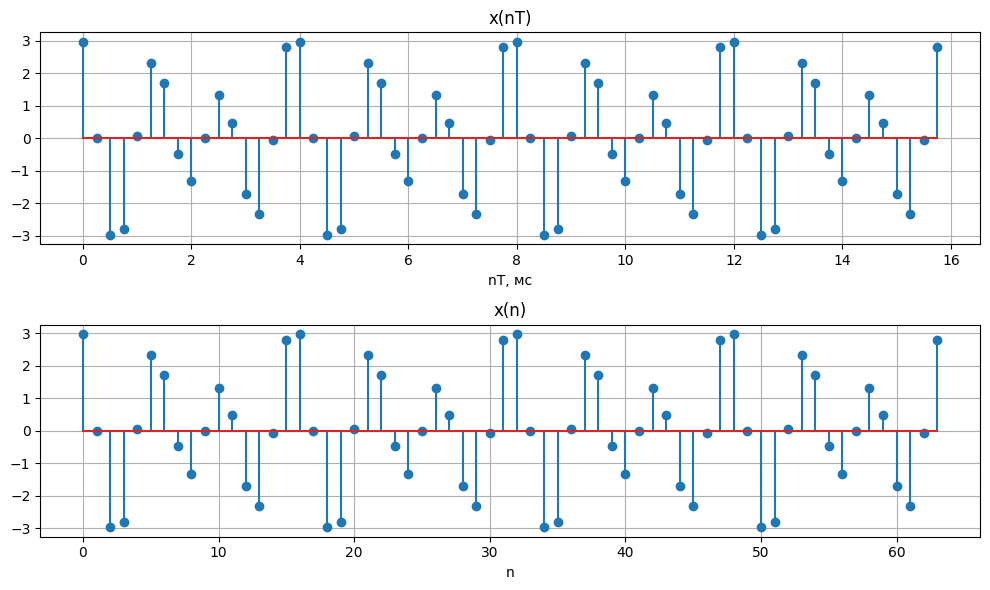

In [15]:
n = np.arange(N)
xn = xa(n * T)

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].stem(n * T * 1e3, xn); ax[0].set_title('x(nT)'); ax[0].set_xlabel('nT, мс')
ax[1].stem(n, xn); ax[1].set_title('x(n)'); ax[1].set_xlabel('n')
plt.tight_layout()
plt.show()

#### Пункт 2. ОДПФ от ДПФ

**Что ищем:** ДПФ последовательности.

В общем виде:

$$ X(k) = \sum_{n=0}^{N-1} x(n)\,e^{-j\frac{2\pi}{N}kn}, \quad k = 0 \ldots N-1. $$

Для варианта 16: $ N = 64 $, множитель $ e^{-j\frac{2\pi}{64}kn} = e^{-j\frac{\pi}{32}kn} $.

In [16]:
X = np.fft.fft(xn)
print('Ненулевые X(k) при k =', np.nonzero(abs(X) > 1e-6 * abs(X).max())[0])

Ненулевые X(k) при k = [ 8 12 52 56]


Вычислим ОДПФ от $ X(k) $ и сравним результат с исходной последовательностью.

Общий вид:

$$ x(n) = \frac{1}{N}\sum_{k=0}^{N-1} X(k)\,e^{j\frac{2\pi}{N}kn}. $$

Подставив сюда формулу ДПФ и воспользовавшись ортогональностью экспонент

$$ \sum_{k=0}^{N-1} e^{j\frac{2\pi}{N}k(n-m)} = \begin{cases} N, & n = m \\ 0, & n \neq m \end{cases}, $$

получаем точно исходную $ x(n) $.

max |Im| = 2.1693674893577825e-30
max |x - IDFT(DFT(x))| = 1.3322676295501878e-15


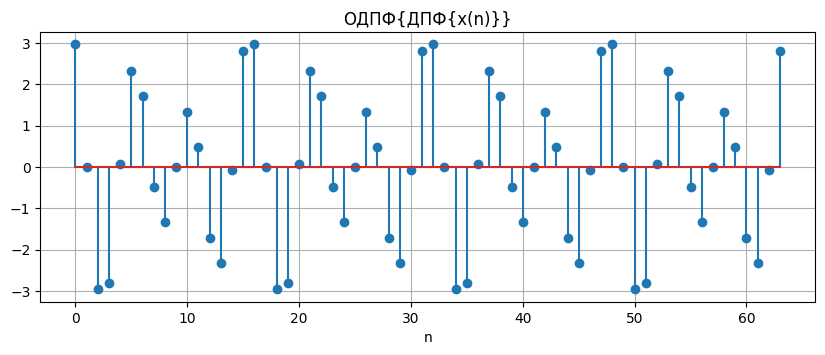

In [17]:
x_rec = np.fft.ifft(X)
print('max |Im| =', np.max(abs(x_rec.imag)))
print('max |x - IDFT(DFT(x))| =', np.max(abs(xn - x_rec)))

plt.stem(n, x_rec.real)
plt.title('ОДПФ{ДПФ{x(n)}}'); plt.xlabel('n')
plt.show()

Последовательность после ОДПФ совпадает с исходной с точностью до ошибок округления ($ \sim 10^{-15} $), мнимая часть практически нулевая: ДПФ и ОДПФ взаимно обратны, информация не теряется.

#### Пункт 3. Амплитудный и фазовый спектры

Найдём $ |X(k)| $ и $ \arg X(k) $ в шкалах $ k $ и $ f $.

Связь шкал частот:

$$ \hat\omega_k = \frac{2\pi k}{N}, \qquad f_k = k\,\frac{f_{д}}{N} = \frac{k}{NT}, \qquad \Delta f = \frac{f_{д}}{N}. $$

Подставляем значения варианта 16: $ \Delta f = 4000/64 = 62.5 $ Гц, $ f_k = 62.5k $ Гц, $ k = 0 \ldots 63 $ соответствует $ f = 0 \ldots 3937.5 $ Гц.

Фазу в точках, где $ |X(k)| \approx 0 $, обнуляем: там $ X(k) $ является ошибкой округления со случайным аргументом.

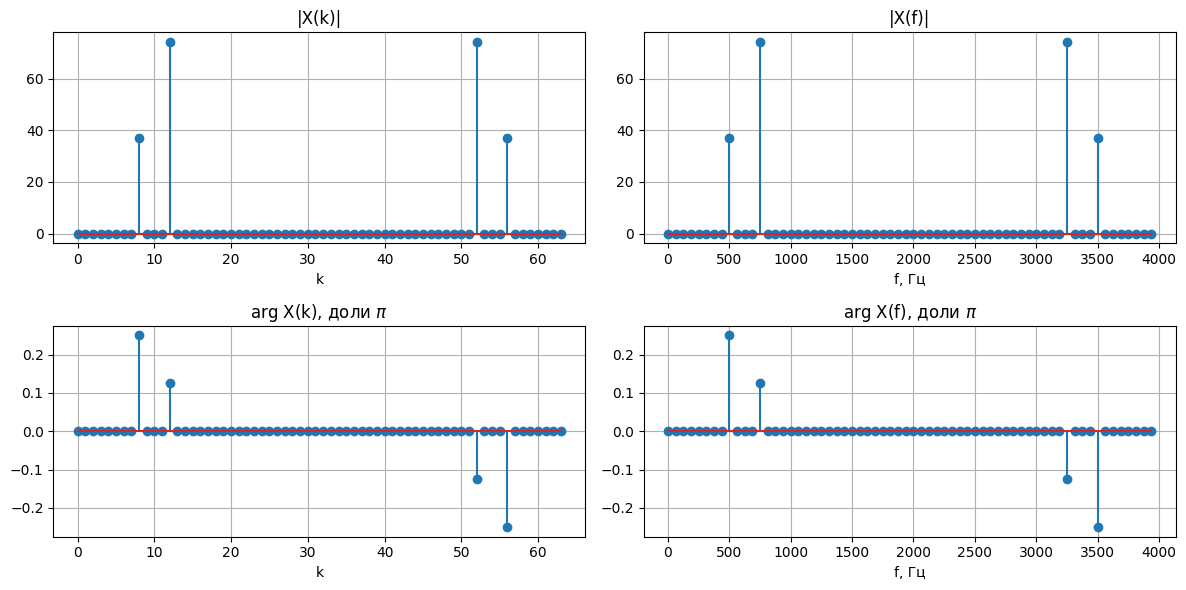

In [18]:
k = np.arange(N)
fk = k * fs2 / N
amp = abs(X)
phase = np.where(amp > 1e-6 * amp.max(), np.angle(X), 0)

fig, ax = plt.subplots(2, 2, figsize=(12, 6))
ax[0, 0].stem(k, amp); ax[0, 0].set_title('|X(k)|'); ax[0, 0].set_xlabel('k')
ax[0, 1].stem(fk, amp); ax[0, 1].set_title('|X(f)|'); ax[0, 1].set_xlabel('f, Гц')
ax[1, 0].stem(k, phase / np.pi); ax[1, 0].set_title(r'arg X(k), доли $\pi$'); ax[1, 0].set_xlabel('k')
ax[1, 1].stem(fk, phase / np.pi); ax[1, 1].set_title(r'arg X(f), доли $\pi$'); ax[1, 1].set_xlabel('f, Гц')
plt.tight_layout()
plt.show()

Найдём теоретические значения спектра.

Общий вид. По формуле Эйлера

$$ A\cos\left(\frac{2\pi k_0}{N}n + \varphi\right) = \frac{A}{2}e^{j\varphi}e^{j\frac{2\pi k_0}{N}n} + \frac{A}{2}e^{-j\varphi}e^{-j\frac{2\pi k_0}{N}n}. $$

Если $ k_0 = f_0N/f_{д} $: целое, то ДПФ отлично от нуля только в двух точках:

$$ X(k_0) = \frac{AN}{2}e^{j\varphi}, \qquad X(N - k_0) = \frac{AN}{2}e^{-j\varphi}. $$

Вариант 16:

$$ k_1 = \frac{500\cdot 64}{4000} = 8, \qquad k_2 = \frac{750\cdot 64}{4000} = 12, $$

$$ |X(8)| = |X(56)| = \frac{1.16\cdot 64}{2} = 37.12, \qquad |X(12)| = |X(52)| = \frac{2.32\cdot 64}{2} = 74.24, $$

$$ \arg X(8) = \frac{\pi}{4}, \quad \arg X(56) = -\frac{\pi}{4}, \quad \arg X(12) = \frac{\pi}{8}, \quad \arg X(52) = -\frac{\pi}{8}. $$

In [19]:
k1, k2 = int(f1 * N / fs2), int(f2 * N / fs2)
print(f'k1 = {k1}, k2 = {k2}; теория: A1*N/2 = {A1*N/2:.2f}, A2*N/2 = {A2*N/2:.2f}')
for i in np.nonzero(amp > 1e-6 * amp.max())[0]:
    print(f'k = {i:2d}, f = {fk[i]:6.1f} Гц, |X| = {amp[i]:.2f}, arg X = {phase[i]/np.pi:+.4f}pi')

k1 = 8, k2 = 12; теория: A1*N/2 = 37.12, A2*N/2 = 74.24
k =  8, f =  500.0 Гц, |X| = 37.12, arg X = +0.2500pi
k = 12, f =  750.0 Гц, |X| = 74.24, arg X = +0.1250pi
k = 52, f = 3250.0 Гц, |X| = 74.24, arg X = -0.1250pi
k = 56, f = 3500.0 Гц, |X| = 37.12, arg X = -0.2500pi


1. Дискретное нормированное время $ n $: номер отсчёта; оно связано с дискретным временем через период дискретизации: $ nT = n\cdot T $, $ T = 0.25 $ мс.
2. Частота в Гц связана с дискретной нормированной частотой $ k $: $ f_k = k f_{д}/N = 62.5k $ Гц (и $ \hat\omega_k = 2\pi k/N $). Гармоникам $ f_1 = 500 $ и $ f_2 = 750 $ Гц соответствуют $ k_1 = 8 $ и $ k_2 = 12 $.
3. Амплитудный спектр содержит 4 ненулевых отсчёта: $ k = 8, 12 $ и симметричные им $ k = 56, 52 $ (отрицательные частоты $ -8, -12 $, сдвинутые на период $ N $). Значения совпадают с теорией $ A_iN/2 $. Растекания спектра нет, так как гармоники точно попадают в отсчёты ДПФ. Амплитудный спектр чётно-симметричен относительно $ N/2 $, фазовый нечётно; фазы в $ k = 8, 12 $ равны начальным фазам гармоник $ \pi/4 $ и $ \pi/8 $.

#### Пункт 4. ДПФ конечной последовательности

**Что ищем:** спектр конечной последовательности и его связь с $ |X(k)| $.

В общем случае конечная последовательность: те же $ N $ отсчётов, вне интервала $ x(n) = 0 $. Её спектр является непрерывной функцией частоты:

$$ X(e^{j\hat\omega}) = \sum_{n=0}^{N-1} x(n)\,e^{-j\hat\omega n}, \qquad X(e^{j\hat\omega})\Big|_{\hat\omega = 2\pi k/N} = X(k). $$

Каждая гармоника даёт в нём лепесток вида

$$ \frac{A}{2}\left|\frac{\sin\big(N(\hat\omega - \hat\omega_0)/2\big)}{\sin\big((\hat\omega - \hat\omega_0)/2\big)}\right|, $$

с максимумом $ AN/2 $ при $ \hat\omega = \hat\omega_0 $ и нулями в точках $ \hat\omega_0 + 2\pi m/N $, $ m \neq 0 $.

Для варианта 16: максимумы при $ \hat\omega = \pi/4 $ ($ k = 8 $) и $ 3\pi/8 $ ($ k = 12 $), нули лепестков попадают точно на остальные целые $ k $.

Для расчёта на густой сетке дополняем последовательность нулями до $ M = 4096 $ отсчётов.

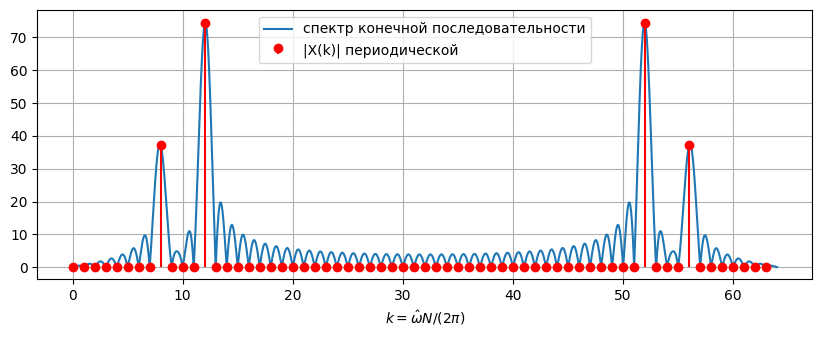

max |X(e^jw_k) - X(k)| = 1.3010227344586376e-29


In [20]:
M = 4096
Xc = np.fft.fft(xn, M)
kc = np.arange(M) * N / M

plt.plot(kc, abs(Xc), label='спектр конечной последовательности')
plt.stem(k, amp, linefmt='r-', markerfmt='ro', basefmt=' ', label='|X(k)| периодической')
plt.xlabel(r'$k = \hat\omega N/(2\pi)$'); plt.legend()
plt.show()

print('max |X(e^jw_k) - X(k)| =', np.max(abs(Xc[::M // N] - X)))

Амплитудный спектр периодической последовательности представляет собой отсчёты модуля непрерывного спектра конечной последовательности в точках $ \hat\omega_k = 2\pi k/N $: красные отсчёты лежат точно на кривой. Поскольку частоты гармоник кратны $ f_{д}/N $, отсчёты попадают в максимумы главных лепестков и в нули боковых, поэтому в $ |X(k)| $ видны только 4 линии.

#### Пункт 5. Восстановление аналогового сигнала

Сформируем отсчёты $ X_a(k) $, $ k = -N/2 \ldots N/2 - 1 $.

Общий вид. Отсчёты ДПФ с $ k > N/2 $ соответствуют отрицательным частотам $ k - N $, поэтому спектр переставляется:

$$ X_a(k) = \begin{cases} X(N+k), & -N/2 \leqslant k \leqslant -1 \\ X(k), & 0 \leqslant k \leqslant N/2 - 1 \end{cases} $$

Подставляем значения варианта 16: $ k = -32 \ldots 31 $; $ X_a(-8) = X(56) $, $ X_a(-12) = X(52) $, $ X_a(8) = X(8) $, $ X_a(12) = X(12) $.

In [21]:
ka = np.arange(-N // 2, N // 2)
Xa = np.where(ka < 0, X[(N + ka) % N], X[ka % N])
print('Ненулевые Xa(k) при k =', ka[abs(Xa) > 1e-6 * abs(Xa).max()])

Ненулевые Xa(k) при k = [-12  -8   8  12]


Вычислим восстановленный сигнал $ x(t) $.

В общем виде:

$$ x(t) = \frac{1}{N}\sum_{k=-N/2}^{N/2-1} X_a(k)\exp\Big(j\frac{2\pi}{NT}kt\Big), \qquad t \in [0; (N-1)T], \quad \Delta t = 0.25T. $$

Слагаемое с номером $ k $: гармоника частоты $ k/(NT) $. Сопряжённые пары $ X_a(\pm k_0) $ дают вещественный косинус: $ \frac{1}{N}\cdot 2\cdot\frac{AN}{2}\cos\big(2\pi\frac{k_0}{NT}t + \varphi\big) = A\cos(2\pi f_0 t + \varphi) $.

Вариант 16: $ NT = 16 $ мс, $ \Delta t = 62.5 $ мкс, число точек $ 4\cdot 63 + 1 = 253 $;

$$ x(t) = 1.16\cos(2\pi\cdot 500\,t + \pi/4) + 2.32\cos(2\pi\cdot 750\,t + \pi/8). $$

In [22]:
t = np.arange(0, (N - 1) * T + T / 8, 0.25 * T)
x_t = (Xa[None, :] * np.exp(1j * 2 * np.pi / (N * T) * np.outer(t, ka))).sum(axis=1) / N
print('Число точек:', len(t), '| max |Im x(t)| =', np.max(abs(x_t.imag)))

Число точек: 253 | max |Im x(t)| = 1.210980754373655e-15


Построим графики и амплитудный спектр восстановленного сигнала.

Общий вид: спектр восстановленного сигнала состоит из линий на частотах $ f = k/(NT) $ высотой

$$ C(k) = \frac{X_a(k)}{N}, \qquad |C(k)| = \frac{|X_a(k)|}{N}. $$

Для варианта 16: линии на $ \pm 500 $ Гц высотой $ 37.12/64 = 0.58 $ и на $ \pm 750 $ Гц высотой $ 74.24/64 = 1.16 $.

Исходный аналоговый сигнал для сравнения: $ x(t) = x(nT)\big|_{nT = t} $.

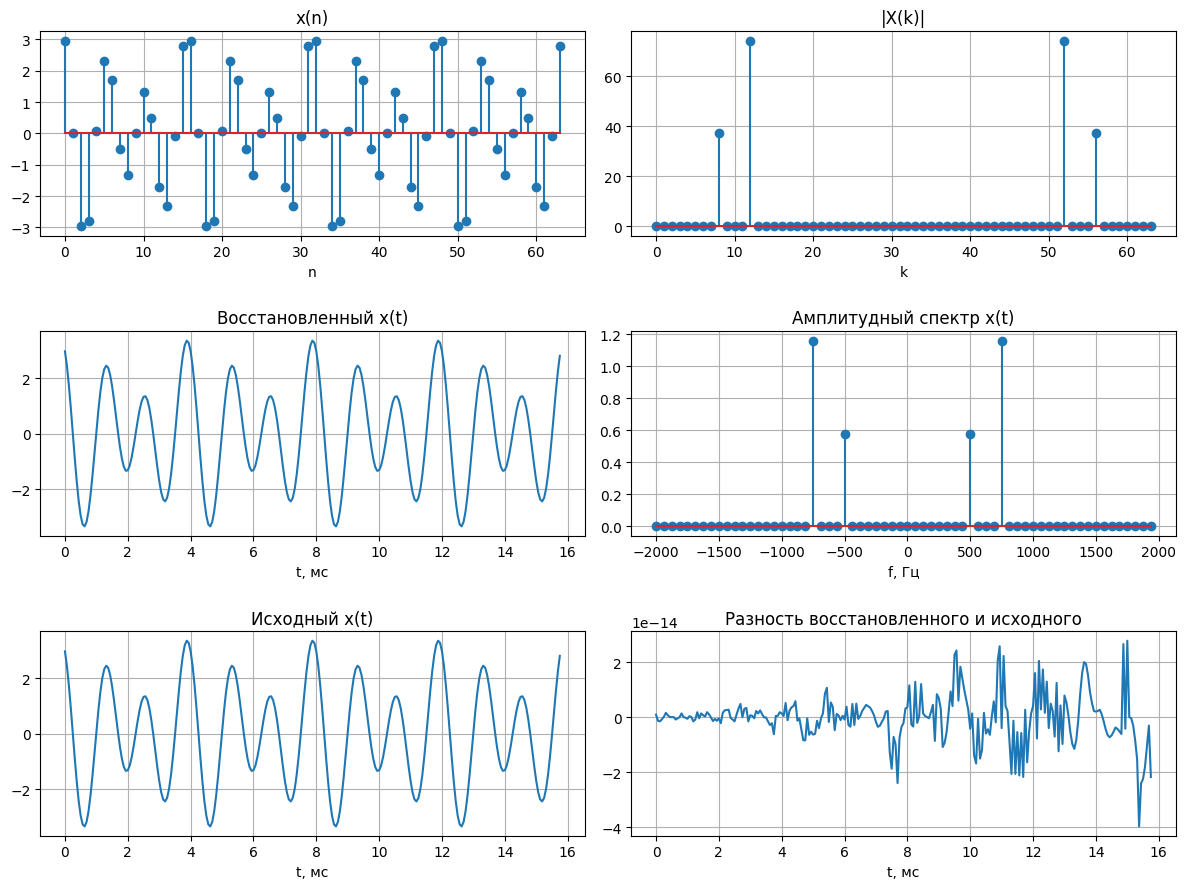

In [23]:
x_orig = xa(t)

fig, ax = plt.subplots(3, 2, figsize=(12, 9))
ax[0, 0].stem(n, xn); ax[0, 0].set_title('x(n)'); ax[0, 0].set_xlabel('n')
ax[0, 1].stem(k, amp); ax[0, 1].set_title('|X(k)|'); ax[0, 1].set_xlabel('k')
ax[1, 0].plot(t * 1e3, x_t.real); ax[1, 0].set_title('Восстановленный x(t)'); ax[1, 0].set_xlabel('t, мс')
ax[1, 1].stem(ka * fs2 / N, abs(Xa) / N); ax[1, 1].set_title('Амплитудный спектр x(t)'); ax[1, 1].set_xlabel('f, Гц')
ax[2, 0].plot(t * 1e3, x_orig); ax[2, 0].set_title('Исходный x(t)'); ax[2, 0].set_xlabel('t, мс')
ax[2, 1].plot(t * 1e3, x_t.real - x_orig); ax[2, 1].set_title('Разность восстановленного и исходного'); ax[2, 1].set_xlabel('t, мс')
plt.tight_layout()
plt.show()

#### Пункт 6. Анализ результатов п. 5

Проверим связь модуля ДПФ со спектром аналогового сигнала и точность восстановления.

В общем случае двусторонний спектр косинуса $ A\cos(2\pi f_0t + \varphi) $ состоит из двух линий $ \pm f_0 $ высотой $ A/2 $, односторонний из одной линии высотой $ A $. Связь с ДПФ:

для двустороннего спектра

$$ \frac{|X_a(\pm k_0)|}{N} = \frac{A}{2}, $$

для одностороннего

$$ \frac{2|X(k_0)|}{N} = A. $$

Подставляем значения варианта 16: $ 2\cdot 37.12/64 = 1.16 = A_1 $, $ 2\cdot 74.24/64 = 2.32 = A_2 $.

In [24]:
for kk, A in ((k1, A1), (k2, A2)):
    c = abs(Xa[ka == kk][0]) / N
    print(f'f = +-{kk*fs2/N:.0f} Гц: |Xa|/N = {c:.4f} (A/2 = {A/2:.4f}), 2|X|/N = {2*c:.4f} (A = {A:.4f})')
print('max |x_rest(t) - x(t)| =', np.max(abs(x_t.real - x_orig)))

f = +-500 Гц: |Xa|/N = 0.5800 (A/2 = 0.5800), 2|X|/N = 1.1600 (A = 1.1600)
f = +-750 Гц: |Xa|/N = 1.1600 (A/2 = 1.1600), 2|X|/N = 2.3200 (A = 2.3200)
max |x_rest(t) - x(t)| = 3.9745984281580604e-14


1. Модуль ДПФ последовательности, делённый на $ N $ и переставленный в порядок $ k = -N/2 \ldots N/2-1 $, совпадает с двусторонним амплитудным спектром аналогового сигнала: линии на $ \pm 500 $ и $ \pm 750 $ Гц высотой $ A_1/2 = 0.58 $ и $ A_2/2 = 1.16 $. Это выполняется, так как спектр сигнала ограничен частотой $ f_2 = 750 < f_{д}/2 = 2000 $ Гц и наложения спектров при дискретизации нет.
2. Восстановленный и исходный сигналы визуально совпадают, разность на уровне ошибок округления ($ \sim 10^{-14} $). Причины: выполнено условие теоремы Котельникова, и на интервале $ NT $ укладывается целое число периодов обеих гармоник, поэтому сигнал точно представляется конечной суммой гармоник с частотами $ k/(NT) $.

#### Пункт 7. Равенство Парсеваля

**Что ищем:** энергию последовательности во временной и частотной областях.

Общий вид:

$$ E = \sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N}\sum_{k=0}^{N-1} |X(k)|^2. $$

Для суммы гармоник с целым числом периодов на $ N $ (средний квадрат косинуса равен $ A^2/2 $):

$$ E = N\,\frac{A_1^2 + A_2^2}{2}. $$

Вариант 16, по спектру:

$$ E = \frac{1}{64}\left(2\cdot 37.12^2 + 2\cdot 74.24^2\right) = \frac{2755.81 + 11023.23}{64} = 215.296, $$

по амплитудам:

$$ E = 64\cdot\frac{1.3456 + 5.3824}{2} = 64\cdot 3.364 = 215.296. $$

In [25]:
E_time = np.sum(abs(xn)**2)
E_freq = np.sum(abs(X)**2) / N
E_theor = N * (A1**2 + A2**2) / 2
print(f'sum |x(n)|^2 = {E_time:.6f}')
print(f'(1/N) sum |X(k)|^2 = {E_freq:.6f}')
print(f'N(A1^2 + A2^2)/2 = {E_theor:.6f}')
print(f'Разность: {abs(E_time - E_freq):.2e}')

sum |x(n)|^2 = 215.296000
(1/N) sum |X(k)|^2 = 215.296000
N(A1^2 + A2^2)/2 = 215.296000
Разность: 2.84e-14


Равенство Парсеваля выполняется: энергия последовательности, вычисленная во временной области, равна энергии, вычисленной по ДПФ, расхождение на уровне ошибок округления.

Смысл равенства: энергия сигнала сохраняется при переходе из временной области в частотную: ДПФ лишь распределяет её по частотным составляющим. Например, на вторую гармонику приходится $ A_2^2/(A_1^2 + A_2^2) = 80\% $ энергии.

## Выводы

В практической работе изучены линейные дискретные системы и частотный анализ дискретных сигналов. Для рекурсивного звена 2-го порядка рассчитаны импульсная характеристика, реакции на прямоугольное воздействие (по формуле свёртки и по разностному уравнению), нули и полюсы, построены карта нулей и полюсов, АЧХ и ФЧХ. Полюсы лежат внутри единичной окружности, следовательно, звено устойчиво. По частотным характеристикам видно, что звено подавляет низкие частоты (нуль АЧХ при 2253 Гц) и резонансно усиливает высокие (максимум около 5988 Гц). Для последовательности варианта 16 получены её временное и частотное представления, вычислены прямое и обратное ДПФ, сопоставлены спектры конечной последовательности и периодической последовательности, восстановлен аналоговый сигнал. Пики спектра на частотах 500 и 750 Гц соответствуют заданным гармоникам, а восстановленный сигнал отличается от исходного не более чем на $10^{-14}$. Равенство Парсеваля выполняется: энергия во временной и в частотной областях равна $215.296$. При анализе результатов необходимо было учитывать нормировку ДПФ и разницу между конечной последовательностью и её периодическим продолжением; эти связи подтверждены расчётами и графиками.